# OncosenseAI – SEER Pancreatic Cancer Analysis (full manuscript pipeline)

**What this notebook does (run top to bottom):**
1. Loads your SEER\*Stat CSV export and auto-detects the columns
2. Builds the analytic cohort (with a CONSORT-style flow table)
3. Table 1, Kaplan–Meier survival, multivariable Cox model
4. 12-month mortality prediction with a **temporal validation split** (train on earlier years, test on later years), bootstrap CIs, calibration, and the 95%-sensitivity operating point
5. Saves every table/figure and auto-writes the key numbers for your Results section

**Important:** SEER contains only people who already have cancer, so this is a **prognosis** analysis, not symptom triage. Do not upload the raw SEER file to GitHub (SEER data-use agreement).

**Before you start:** in SEER\*Stat export with *CSV Defaults*, tick *Output variable names before data*, and use *Labels enclosed in Quotes*.

In [1]:
!pip -q install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, re, io, json, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ------------------ SETTINGS (edit here) ------------------
OUT          = "oncosense_outputs"   # all results are saved here
SEED         = 42
YEAR_MIN     = 2004                  # diagnosis years to include
YEAR_MAX     = 2022
TEST_FROM    = 2018                  # temporal validation: train < 2018, test >= 2018
HORIZON      = 12                    # months, for the mortality-prediction task
ML_YEAR_MAX  = 2021                  # last dx year for ML: later cases lack 12 months of follow-up (SEER follow-up ends ~Dec 2022)
TARGET_SENS  = 0.95                  # sensitivity for the operating-point analysis
N_BOOT       = 500                   # bootstrap resamples for AUROC CI
# -----------------------------------------------------------
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Ready.")

Ready.


## 1. Load data

In [3]:
# Option A (default): upload the CSV from your computer.
# Option B: for very large files, mount Google Drive and set DATA_PATH manually, e.g.
#   from google.colab import drive; drive.mount('/content/drive')
#   DATA_PATH = '/content/drive/MyDrive/SEER_pancreas.csv'

DATA_PATH = os.environ.get("SEER_CSV")          # used only for offline testing
if DATA_PATH is None:
    try:
        from google.colab import files
        up = files.upload()
        DATA_PATH = list(up.keys())[0]
    except ImportError:
        DATA_PATH = "SEER_pancreas.csv"

def load_seer(path):
    with open(path, "rb") as f: head = f.read(4096)
    print(f"File size: {os.path.getsize(path)/1e6:.1f} MB | first bytes: {head[:60]!r}")
    comp = None
    if head[:2] == b"\x1f\x8b": comp = "gzip"
    elif head[:2] == b"PK":
        raise ValueError("This is an Excel/ZIP file, not a CSV. Re-export from SEER*Stat as CSV (or unzip it first).")
    encs = (["utf-16"] if head[:2] in (b"\xff\xfe", b"\xfe\xff") else []) + ["utf-8-sig", "cp1252", "latin-1"]
    first_line = head.decode("latin-1", errors="ignore").split("\n")[0]
    sep = "\t" if first_line.count("\t") > first_line.count(",") else ","
    last_err = None
    for enc in encs:
        try:
            df = pd.read_csv(path, sep=sep, dtype=str, low_memory=False, encoding=enc, compression=comp)
            sep_name = "TAB" if sep == "\t" else "COMMA"
            print(f"Loaded OK with encoding={enc!r}, delimiter={sep_name}")
            return df
        except UnicodeError as e:
            last_err = e
            print(f"  encoding {enc!r} failed, trying next...")
    raise last_err

raw = load_seer(DATA_PATH)
raw.columns = [c.strip().strip('"') for c in raw.columns]
print("Shape:", raw.shape, "(expect roughly 266,000 rows for full pancreas 2000-2022; far fewer means the export was filtered or cut off)")
if not any(re.search(r"age recode|year of diagnosis|survival months", c, re.I) for c in raw.columns):
    print("!! Header row not recognised. Column names found:", list(raw.columns)[:8],
          "\n   Re-export with 'Output variable names before data' ticked.")
raw.head(3)

Saving seer_pancreas.csv to seer_pancreas.csv
File size: 93.2 MB | first bytes: b'Age recode with <1 year olds and 90+,Sex,Year of diagnosis,"'
Loaded OK with encoding='utf-8-sig', delimiter=COMMA
Shape: (266170, 35) (expect roughly 266,000 rows for full pancreas 2000-2022; far fewer means the export was filtered or cut off)


,Age recode with <1 year olds and 90+,Sex,Year of diagnosis,"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",Site recode ICD-O-3/WHO 2008,Behavior code ICD-O-3,TNM 7/CS v0204+ Schema recode,Primary Site,Behavior recode for analysis,Grade Recode (thru 2017),...,SEER other cause of death classification,Survival months,Survival Days,Survival months flag,Site recode ICD-O-3 2023 Revision,Primary Site - labeled,Site recode ICD-O-3/WHO 2008 (for SIRs),Total number of in situ/malignant tumors for patient,"ICD-O-3 Hist/behav, malignant",RX Summ--Reg LN Examined (1998-2002)
0,00 years,Male,2010,Hispanic (All Races),Pancreas,Malignant,PancreasBodyTail,252,Malignant,Unknown,...,Alive or dead due to cancer,160,4892,Complete dates are available and there are mor...,Pancreas,C25.2-Tail of pancreas,Pancreas,1,8971/3: Pancreatoblastoma,Blank(s)
1,00 years,Male,2016,Non-Hispanic Asian or Pacific Islander,Pancreas,Malignant,PancreasOther,259,Malignant,Unknown,...,Alive or dead due to cancer,10,328,Complete dates are available and there are mor...,Pancreas,"C25.9-Pancreas, NOS",Pancreas,1,8971/3: Pancreatoblastoma,Blank(s)
2,00 years,Male,2017,Non-Hispanic White,Pancreas,Malignant,PancreasOther,259,Malignant,Unknown,...,Alive or dead due to cancer,69,2101,Complete dates are available and there are mor...,Pancreas,"C25.9-Pancreas, NOS",Pancreas,1,8971/3: Pancreatoblastoma,Blank(s)


## 2. Detect columns (check this printout!)

In [4]:
PATTERNS = {
 "age":      [r"^age recode"],
 "sex":      [r"^sex$"],
 "race":     [r"^race and origin recode", r"^race recode", r"^race"],
 "year":     [r"^year of diagnosis$"],
 "months":   [r"^survival months$"],
 "flag":     [r"^survival months flag"],
 "vital":    [r"^vital status recode", r"^vital status"],
 "csd":      [r"^seer cause-specific death"],
 "seq":      [r"^sequence number"],
 "site":     [r"^primary site - labeled", r"^site recode icd-o-3/who 2008$", r"^primary site$", r"^site recode"],
 "hist":     [r"^histologic type icd-o-3", r"^histology recode", r"^histologic"],
 "behavior": [r"^behavior recode", r"^behavior code"],
 "grade":    [r"^grade recode", r"^grade pathological", r"^grade clinical"],
 "stage":    [r"combined summary stage", r"summary stage 2000", r"^seer historic stage", r"summary stage"],
 "size":     [r"^tumor size summary", r"^cs tumor size", r"tumor size"],
 "surgery":  [r"^rx summ.*surg prim site", r"surg prim site"],
 "radiation":[r"^radiation recode", r"^radiation"],
 "chemo":    [r"^chemotherapy recode", r"^chemotherapy"],
 "marital":  [r"^marital status"],
}

# ---- MANUAL OVERRIDES (optional) ----
# e.g. OVERRIDE = {"surgery": ["RX Summ--Surg Prim Site (1998-2022)"]}
OVERRIDE = {}

def find_cols(pats):
    hits = []
    for p in pats:
        for c in raw.columns:
            if re.search(p, c, flags=re.I) and c not in hits:
                hits.append(c)
    return hits

colmap = {k: find_cols(v) for k, v in PATTERNS.items()}
for k, v in OVERRIDE.items():
    colmap[k] = [c for c in v if c in raw.columns]
    bad = [c for c in v if c not in raw.columns]
    if bad: print(f"!! OVERRIDE for '{k}' not found in file: {bad}")

MULTI = {"stage", "grade", "size"}          # these are coalesced across several columns
for k in colmap:
    if k not in MULTI and len(colmap[k]) > 1:
        colmap[k] = colmap[k][:1]

BLANKS = {"blank(s)", "unknown", "unstaged", "unknown/unstaged", "na", "nan", "", "not applicable"}
def coverage(c):
    s = raw[c].astype("string").str.strip().str.lower()
    return 1 - (s.isna() | s.isin(BLANKS)).mean()

print(f"{'variable':10s} {'coverage':>8s}   column")
for k, v in colmap.items():
    if not v: print(f"{k:10s} {'':>8s}   -- NOT FOUND --")
    for c in v: print(f"{k:10s} {coverage(c):8.0%}   {c}")

REQUIRED = ["age", "sex", "year", "months", "vital"]
missing_req = [k for k in REQUIRED if not colmap[k]]
assert not missing_req, f"Required columns missing from export: {missing_req}. Add them in SEER*Stat or set OVERRIDE."
RECOMMENDED = ["site", "hist", "stage", "seq", "flag", "surgery", "chemo", "radiation", "marital", "size"]
warn = [k for k in RECOMMENDED if not colmap[k]]
if warn: print("\n!! Recommended variables missing (analysis will run without them, with limits):", warn)

variable   coverage   column
age            100%   Age recode with <1 year olds and 90+
sex            100%   Sex
race           100%   Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)
year           100%   Year of diagnosis
months         100%   Survival months
flag           100%   Survival months flag
vital          100%   Vital status recode (study cutoff used)
csd            100%   SEER cause-specific death classification
seq            100%   Sequence number
site           100%   Primary Site - labeled
hist           100%   Histologic Type ICD-O-3
behavior       100%   Behavior recode for analysis
grade           99%   Grade Recode (thru 2017)
stage          100%   Combined Summary Stage with Expanded Regional Codes (2004+)
stage           69%   Summary stage 2000 (1998-2017)
stage           86%   SEER historic stage A (1973-2015)
size           100%   Tumor Size Summary (2016+)
size           100%   CS tumor size (2004-2015)
surgery        100%   RX Summ--Surg Prim Sit

## 3. Clean variables

In [5]:
MISSING = {"blank(s)", "unknown", "unstaged", "unknown/unstaged", "na", "nan", "", "not applicable", "unk", "not available"}
def clean(s):
    s = s.astype("string").str.strip()
    return s.mask(s.str.lower().isin(MISSING))

def coalesce(cols, fn=lambda s: s):
    out = None
    for c in cols:
        v = fn(clean(raw[c]))
        out = v if out is None else out.combine_first(v)
    return out

def parse_age(x):
    if pd.isna(x): return np.nan
    x = str(x)
    m = re.match(r"(\d+)\s*-\s*(\d+)", x)
    if m: return (int(m.group(1)) + int(m.group(2))) / 2
    m = re.match(r"(\d+)\s*\+", x)
    if m: return int(m.group(1)) + 2
    m = re.match(r"^(\d+)", x)
    if m: return float(m.group(1))
    if x.startswith("<1"): return 0.5
    return np.nan

def map_stage(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if "local" in t: return "Localized"
    if "regional" in t: return "Regional"
    if "distant" in t: return "Distant"
    return np.nan

def map_grade(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if re.search(r"grade iv\b|undiff|anaplast|grade iii\b|poor", t) or t in {"3", "4"}: return "G3-4"
    if re.search(r"grade ii\b|moderate", t) or t == "2": return "G2"
    if re.search(r"grade i\b|well", t) or t == "1": return "G1"
    return np.nan

def hist_group(x):
    if pd.isna(x): return "Unknown"
    m = re.search(r"(\d{4})", x)
    if not m: return "Unknown"
    h = int(m.group(1))
    if h in (8140, 8141, 8500, 8480, 8481, 8255, 8260, 8211): return "Adenocarcinoma"
    if 8150 <= h <= 8158 or 8240 <= h <= 8249: return "Neuroendocrine"
    return "Other"

def map_surg(x):
    if pd.isna(x): return np.nan
    t = x.lower().strip()
    if t.startswith("none") or "not recommended" in t or t in {"0", "00"}: return "No"
    if "unknown" in t or "recommended" in t or "refused" in t or t in {"99", "126"}: return np.nan
    return "Yes"

def map_rad(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if t.startswith("none") or "refused" in t: return "No/Unk"
    if "unknown if" in t or "recommended" in t: return np.nan
    return "Yes"

def map_chemo(x):
    if pd.isna(x): return np.nan
    return "Yes" if x.lower().startswith("yes") else "No/Unk"

def parse_size(s):
    v = pd.to_numeric(s, errors="coerce")
    return v.where((v >= 1) & (v <= 988))

d = pd.DataFrame(index=raw.index)
d["age"]    = clean(raw[colmap["age"][0]]).map(parse_age).astype(float)
d["sex"]    = clean(raw[colmap["sex"][0]])
d["race"]   = clean(raw[colmap["race"][0]]) if colmap["race"] else pd.NA
d["year"]   = pd.to_numeric(raw[colmap["year"][0]], errors="coerce")
d["time"]   = pd.to_numeric(raw[colmap["months"][0]], errors="coerce")
d["event"]  = (clean(raw[colmap["vital"][0]]).str.lower() == "dead").astype(int)
d["cs_event"] = (clean(raw[colmap["csd"][0]]).str.contains("attributable", case=False, na=False)).astype(int) if colmap["csd"] else np.nan
d["stage"]  = coalesce(colmap["stage"], lambda s: s.map(map_stage)) if colmap["stage"] else pd.NA
d["grade"]  = coalesce(colmap["grade"], lambda s: s.map(map_grade)) if colmap["grade"] else pd.NA
d["hist_group"] = clean(raw[colmap["hist"][0]]).map(hist_group) if colmap["hist"] else "Unknown"
d["tumor_size"] = None
if colmap["size"]:
    sz = None
    for c in colmap["size"]:
        v = parse_size(raw[c]); sz = v if sz is None else sz.combine_first(v)
    d["tumor_size"] = sz
d["marital"]   = clean(raw[colmap["marital"][0]]) if colmap["marital"] else pd.NA
d["surgery"]   = clean(raw[colmap["surgery"][0]]).map(map_surg) if colmap["surgery"] else pd.NA
d["radiation"] = clean(raw[colmap["radiation"][0]]).map(map_rad) if colmap["radiation"] else pd.NA
d["chemo"]     = clean(raw[colmap["chemo"][0]]).map(map_chemo) if colmap["chemo"] else pd.NA
d["tumor_size"] = pd.to_numeric(d["tumor_size"], errors="coerce")

# --- cohort filters (flow table) ---
flow = [("Records in SEER export", len(raw))]
keep = pd.Series(True, index=d.index)
def step(label, mask):
    global keep
    keep = keep & mask.fillna(False)
    flow.append((label, int(keep.sum())))

if colmap["site"]:
    s = raw[colmap["site"][0]].astype("string")
    step("Pancreas primary (C25.x)", s.str.contains(r"C25|pancrea", case=False, na=False) | s.str.match(r"^\s*25\d\s*$", na=False))
if colmap["behavior"]:
    step("Malignant behavior", raw[colmap["behavior"][0]].astype("string").str.contains("malignant", case=False, na=False))
step(f"Diagnosed {YEAR_MIN}-{YEAR_MAX}", d["year"].between(YEAR_MIN, YEAR_MAX))
if colmap["seq"]:
    s = raw[colmap["seq"][0]].astype("string")
    step("First/only primary (one record per patient)", s.str.contains(r"One primary only|1st of", case=False, na=False))
step("Valid survival time", d["time"].notna())
if colmap["flag"]:
    step("Excl. death-certificate/autopsy-only", ~raw[colmap["flag"][0]].astype("string").str.contains("Not calculated", case=False, na=False))
step("Known age and sex", d["age"].notna() & d["sex"].notna())

d = d[keep].copy()
for c in ["race", "marital", "stage", "grade", "surgery", "radiation", "chemo"]:
    d[c] = d[c].astype("object").where(d[c].notna(), "Unknown")
d["stage"] = pd.Categorical(d["stage"], ["Localized", "Regional", "Distant", "Unknown"])

flow_df = pd.DataFrame(flow, columns=["Step", "N remaining"])
flow_df.to_csv(f"{OUT}/cohort_flow.csv", index=False)
display(flow_df)
print(f"Final analytic cohort: n = {len(d):,}")

,Step,N remaining
0,Records in SEER export,266170
1,Pancreas primary (C25.x),2000
2,Malignant behavior,2000
3,Diagnosed 2004-2022,1545
4,First/only primary (one record per patient),1474
5,Valid survival time,1466
6,Excl. death-certificate/autopsy-only,1466
7,Known age and sex,1466


Final analytic cohort: n = 1,466


### Sanity check: category counts (verify mappings look right)

In [6]:
for c in ["sex", "race", "stage", "grade", "hist_group", "surgery", "radiation", "chemo", "marital"]:
    print(f"--- {c} ---"); print(d[c].value_counts(dropna=False).head(8).to_string(), "\n")
print("Follow-up (months): median", d.time.median(), "| deaths:", int(d.event.sum()), f"({d.event.mean():.1%})")
print("Missing tumor size:", f"{d.tumor_size.isna().mean():.1%}")

--- sex ---
sex
Female    918
Male      548 

--- race ---
race
Non-Hispanic White                            667
Hispanic (All Races)                          432
Non-Hispanic Black                            185
Non-Hispanic Asian or Pacific Islander        157
Non-Hispanic American Indian/Alaska Native     13
Non-Hispanic Unknown Race                      12 

--- stage ---
stage
Localized    656
Distant      445
Regional     297
Unknown       68 

--- grade ---
grade
Unknown    1038
G1          228
G2          120
G3-4         80 

--- hist_group ---
hist_group
Neuroendocrine    582
Other             572
Adenocarcinoma    312 

--- surgery ---
surgery
Yes        890
No         567
Unknown      9 

--- radiation ---
radiation
Unknown    1466 

--- chemo ---
chemo
No/Unk    1030
Yes        436 

--- marital ---
marital
Single (never married)            885
Married (including common law)    452
Unknown                            61
Divorced                           28
Separated      

## 4. Table 1

In [7]:
def fmt_cont(s): return f"{s.median():.1f} ({s.quantile(.25):.1f}-{s.quantile(.75):.1f})"
def table1(d, by="stage"):
    groups = [("Overall", d)] + [(str(k), g) for k, g in d.groupby(by, observed=True)]
    rows = []
    def add_cont(label, col):
        rows.append([label + ", median (IQR)"] + [fmt_cont(g[col].dropna()) if g[col].notna().any() else "-" for _, g in groups])
    def add_cat(label, col):
        rows.append([f"**{label}**"] + [""] * len(groups))
        for lv in d[col].astype(str).value_counts().index:
            rows.append([f"   {lv}"] + [f"{(g[col].astype(str) == lv).sum():,} ({(g[col].astype(str) == lv).mean():.1%})" for _, g in groups])
    rows.append(["N"] + [f"{len(g):,}" for _, g in groups])
    add_cont("Age, years", "age")
    add_cat("Sex", "sex"); add_cat("Race", "race"); add_cat("Histology", "hist_group"); add_cat("Grade", "grade")
    if d.tumor_size.notna().any(): add_cont("Tumor size, mm", "tumor_size")
    for lab, col in [("Surgery", "surgery"), ("Chemotherapy", "chemo"), ("Radiation", "radiation")]:
        if (d[col] != "Unknown").any(): add_cat(lab, col)
    rows.append(["Follow-up, months, median (IQR)"] + [fmt_cont(g["time"]) for _, g in groups])
    rows.append(["Deaths, n (%)"] + [f"{int(g.event.sum()):,} ({g.event.mean():.1%})" for _, g in groups])
    return pd.DataFrame(rows, columns=["Characteristic"] + [n for n, _ in groups])
t1 = table1(d)
t1.to_csv(f"{OUT}/table1.csv", index=False)
display(t1)

,Characteristic,Overall,Localized,Regional,Distant,Unknown
0,N,"1,466",656,297,445,68
1,"Age, years, median (IQR)",27.0 (22.0-32.0),27.0 (22.0-32.0),32.0 (27.0-32.0),32.0 (27.0-32.0),27.0 (22.0-32.0)
2,**Sex**,,,,,
3,Female,918 (62.6%),487 (74.2%),159 (53.5%),228 (51.2%),44 (64.7%)
4,Male,548 (37.4%),169 (25.8%),138 (46.5%),217 (48.8%),24 (35.3%)
5,**Race**,,,,,
6,Non-Hispanic White,667 (45.5%),296 (45.1%),117 (39.4%),222 (49.9%),32 (47.1%)
7,Hispanic (All Races),432 (29.5%),210 (32.0%),96 (32.3%),106 (23.8%),20 (29.4%)
8,Non-Hispanic Black,185 (12.6%),66 (10.1%),42 (14.1%),66 (14.8%),11 (16.2%)
9,Non-Hispanic Asian or Pacific Islander,157 (10.7%),71 (10.8%),38 (12.8%),45 (10.1%),3 (4.4%)


## 5. Kaplan–Meier survival

,Group,N,Deaths,Median OS (mo),Median 95% CI,12-mo OS,24-mo OS,60-mo OS
0,All patients,1466,496,inf,191.0-inf,82.0% (79.9%-83.9%),74.8% (72.5%-77.0%),66.0% (63.3%-68.6%)
1,Localized,656,38,inf,inf-inf,97.9% (96.5%-98.8%),97.4% (95.8%-98.4%),95.7% (93.6%-97.1%)
2,Regional,297,102,inf,155.0-inf,87.7% (83.3%-91.0%),78.6% (73.3%-82.9%),68.0% (62.0%-73.3%)
3,Distant,445,337,15.0,12.0-19.0,54.1% (49.3%-58.7%),38.7% (34.0%-43.3%),21.7% (17.7%-26.0%)


Log-rank test across stages: chi2 = 740.3, p = 1.79e-161


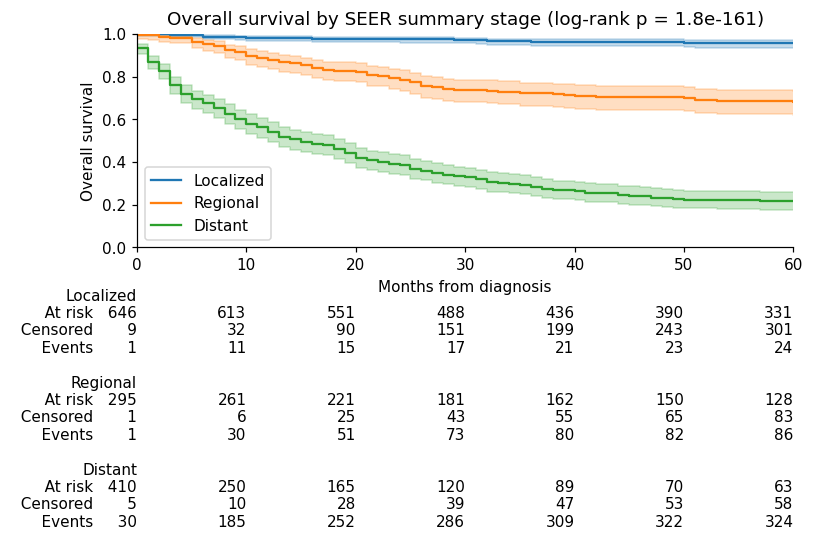

In [8]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times
from lifelines.plotting import add_at_risk_counts

def surv_at(kmf, t):
    sf = kmf.survival_function_at_times([t]).values[0]
    ci = kmf.confidence_interval_survival_function_
    row = ci.loc[:t].iloc[-1]
    return sf, row.iloc[0], row.iloc[1]

def km_summary(g, label):
    k = KaplanMeierFitter().fit(g.time, g.event, label=label)
    med = k.median_survival_time_
    mci = median_survival_times(k.confidence_interval_).iloc[0]
    out = {"Group": label, "N": len(g), "Deaths": int(g.event.sum()), "Median OS (mo)": med,
           "Median 95% CI": f"{mci.iloc[0]:.1f}-{mci.iloc[1]:.1f}"}
    for t in (12, 24, 60):
        sf, lo, hi = surv_at(k, t)
        out[f"{t}-mo OS"] = f"{sf:.1%} ({lo:.1%}-{hi:.1%})"
    return out, k

rows, kms = [], []
r, k_all = km_summary(d, "All patients"); rows.append(r)
staged = d[d.stage.isin(["Localized", "Regional", "Distant"])]
for st in ["Localized", "Regional", "Distant"]:
    g = staged[staged.stage == st]
    if len(g) > 20:
        r, k = km_summary(g, st); rows.append(r); kms.append(k)
km_tab = pd.DataFrame(rows); km_tab.to_csv(f"{OUT}/km_summary.csv", index=False); display(km_tab)

lr = multivariate_logrank_test(staged.time, staged.stage.astype(str), staged.event)
print(f"Log-rank test across stages: chi2 = {lr.test_statistic:.1f}, p = {lr.p_value:.2e}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for k in kms: k.plot_survival_function(ax=ax, ci_show=True)
ax.set_xlim(0, 60); ax.set_ylim(0, 1); ax.set_xlabel("Months from diagnosis"); ax.set_ylabel("Overall survival")
ax.set_title(f"Overall survival by SEER summary stage (log-rank p = {lr.p_value:.1e})")
try: add_at_risk_counts(*kms, ax=ax)
except Exception as e: print("risk table skipped:", e)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_km_by_stage.png", dpi=300); plt.show()

## 6. Multivariable Cox regression

,HR,CI_low,CI_high,p
covariate,,,,
age_per10yr,1.409,1.171,1.695,0.000
male,1.269,1.059,1.520,0.010
dx_year_per5,0.880,0.804,0.964,0.006
stage_Regional,3.880,2.636,5.712,0.000
stage_Distant,13.155,9.167,18.878,0.000
stage_Unknown,4.040,2.306,7.078,0.000
grade_G2,1.077,0.690,1.681,0.746
grade_G3-4,1.996,1.287,3.095,0.002
grade_Unknown,1.741,1.202,2.519,0.003


Concordance (C-index): 0.870


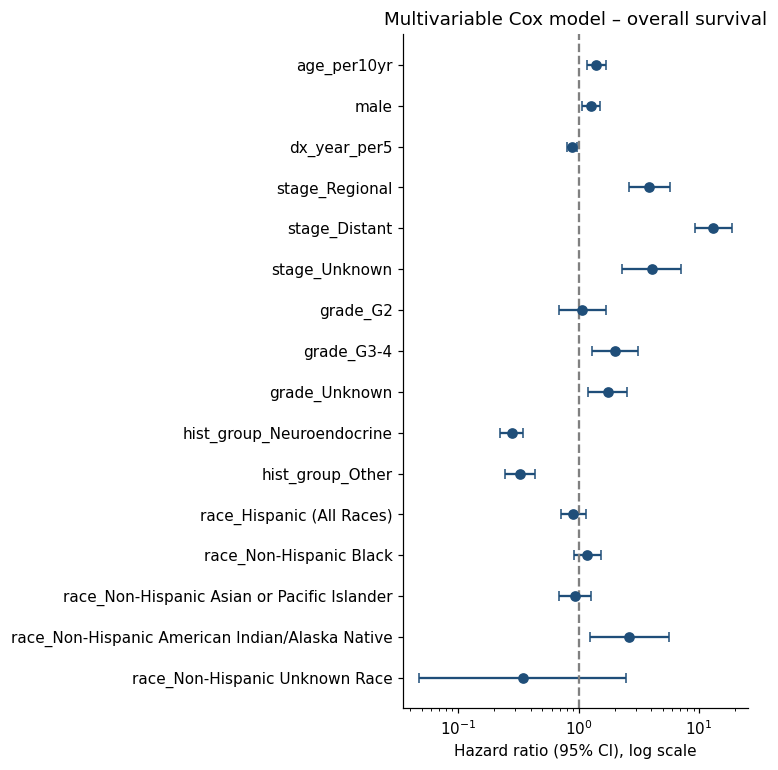

Proportional-hazards test (Schoenfeld):


,test_statistic,p,-log2(p)
age_per10yr,0.0740,0.7856,0.3482
dx_year_per5,0.4369,0.5086,0.9754
grade_G2,0.0258,0.8724,0.1970
grade_G3-4,0.9265,0.3358,1.5744
grade_Unknown,0.2597,0.6104,0.7123
hist_group_Neuroendocrine,2.2282,0.1355,2.8835
hist_group_Other,14.6068,0.0001,12.8824
male,0.2301,0.6315,0.6632
race_Hispanic (All Races),0.9094,0.3403,1.5553
race_Non-Hispanic American Indian/Alaska Native,0.0096,0.9218,0.1175


Note: with large n, small p-values are common; report this as a limitation if any covariate violates PH.


In [9]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

def dummies(col, order=None):
    s = d[col].astype(str)
    cats = order or list(s.value_counts().index)
    s = pd.Categorical(s, [c for c in cats if c in set(s)])
    return pd.get_dummies(s, prefix=col, drop_first=True, dtype=float).set_index(d.index)

X = pd.DataFrame({"age_per10yr": d.age / 10, "male": (d.sex == "Male").astype(float),
                  "dx_year_per5": (d.year - YEAR_MIN) / 5}, index=d.index)
parts = [X, dummies("stage", ["Localized", "Regional", "Distant", "Unknown"]),
         dummies("grade", ["G1", "G2", "G3-4", "Unknown"]),
         dummies("hist_group", ["Adenocarcinoma", "Neuroendocrine", "Other", "Unknown"]),
         dummies("race")]
cox_df = pd.concat(parts, axis=1)
cox_df = cox_df.loc[:, cox_df.std() > 0]
cox_df["time"] = d.time.clip(lower=0.5); cox_df["event"] = d.event

cph = CoxPHFitter().fit(cox_df, "time", "event")
res = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
res.columns = ["HR", "CI_low", "CI_high", "p"]
res.to_csv(f"{OUT}/cox_hazard_ratios.csv"); display(res.round(3))
print(f"Concordance (C-index): {cph.concordance_index_:.3f}")

fig, ax = plt.subplots(figsize=(7, 0.35 * len(res) + 1.5))
y = np.arange(len(res))[::-1]
ax.errorbar(res.HR, y, xerr=[res.HR - res.CI_low, res.CI_high - res.HR], fmt="o", color="#1f4e79", capsize=3)
ax.axvline(1, color="grey", ls="--"); ax.set_yticks(y); ax.set_yticklabels(res.index); ax.set_xscale("log")
ax.set_xlabel("Hazard ratio (95% CI), log scale"); ax.set_title("Multivariable Cox model – overall survival")
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_cox_forest.png", dpi=300); plt.show()

try:
    sub = cox_df.sample(min(len(cox_df), 20000), random_state=SEED)
    ph = proportional_hazard_test(CoxPHFitter().fit(sub, "time", "event"), sub, time_transform="rank")
    print("Proportional-hazards test (Schoenfeld):"); display(ph.summary.round(4))
    print("Note: with large n, small p-values are common; report this as a limitation if any covariate violates PH.")
except Exception as e:
    print("PH test skipped:", e)

## 7. 12-month mortality prediction (temporal validation)

* **Outcome:** death within 12 months of diagnosis. Patients alive but followed for <12 months are excluded (outcome unknown).
* **Split:** train on earlier diagnosis years, test on later years (more realistic than random CV).
* **Feature set A (baseline, at diagnosis):** age, sex, race, marital status, histology, grade, stage, tumor size.
* **Feature set B (A + treatment):** adds surgery, chemotherapy, radiation. Treatment is decided *after* diagnosis and surgery selects patients who survive long enough (immortal-time bias), so report B as exploratory only.
* No survival-time, vital-status or cause-of-death variable is ever used as a feature (checked automatically below).

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

m = d[d.year <= ML_YEAR_MAX].copy()
m["y"] = np.where((m.event == 1) & (m.time < HORIZON), 1, np.where(m.time >= HORIZON, 0, np.nan))
m = m.dropna(subset=["y"]).copy(); m["y"] = m["y"].astype(int)
m["stage"] = m["stage"].astype(str)
print(f"ML cohort: {len(m):,} | {HORIZON}-month mortality: {m.y.mean():.1%}")

NUM = ["age"] + (["tumor_size"] if m.tumor_size.notna().any() else [])
CAT_A = [c for c in ["sex", "race", "marital", "hist_group", "grade", "stage"] if m[c].nunique() > 1]
TX = [c for c in ["surgery", "chemo", "radiation"] if (m[c] != "Unknown").any()]
FEATURE_SETS = {"A_baseline": NUM + CAT_A, "B_plus_treatment": NUM + CAT_A + TX}

banned = re.compile(r"surviv|vital|death|cod|csd|event|time", re.I)
for name, feats in FEATURE_SETS.items():
    bad = [f for f in feats if banned.search(f)]
    assert not bad, f"Leakage risk in {name}: {bad}"
print("Leakage check passed. Feature sets:", {k: v for k, v in FEATURE_SETS.items()})

train = m[m.year < TEST_FROM]; test = m[m.year >= TEST_FROM]
if len(test) < 300 or test.y.nunique() < 2 or train.y.nunique() < 2:
    print("!! Test period too small; falling back to a random 75/25 split (not temporal).")
    test = m.sample(frac=0.25, random_state=SEED); train = m.drop(test.index)
print(f"Train n = {len(train):,} (dx < {TEST_FROM}) | Test n = {len(test):,} (dx >= {TEST_FROM})")

def make_models(feats):
    num = [f for f in feats if f in NUM]; cat = [f for f in feats if f not in NUM]
    def pre(scale):
        n = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
        return ColumnTransformer([("num", Pipeline(n), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return {
        "Logistic Regression": Pipeline([("pre", pre(True)), ("clf", LogisticRegression(max_iter=3000, C=1.0))]),
        "Random Forest": Pipeline([("pre", pre(False)), ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=30, max_samples=0.5, n_jobs=-1, random_state=SEED))]),
        "Gradient Boosting": Pipeline([("pre", pre(False)), ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED))]),
    }

def boot_ci(y, p, fn, n=N_BOOT):
    rng = np.random.default_rng(SEED); vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max(): continue
        vals.append(fn(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

def thr_at_sens(y, p, sens):
    fpr, tpr, thr = roc_curve(y, p); return thr[np.argmax(tpr >= sens)]

def op_metrics(y, p, thr):
    pred = p >= thr; tp = ((pred) & (y == 1)).sum(); fp = ((pred) & (y == 0)).sum()
    tn = ((~pred) & (y == 0)).sum(); fn = ((~pred) & (y == 1)).sum()
    return dict(Sensitivity=tp / max(tp + fn, 1), Specificity=tn / max(tn + fp, 1), PPV=tp / max(tp + fp, 1), NPV=tn / max(tn + fn, 1))

results, test_preds, fitted = [], {}, {}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for fs_name, feats in FEATURE_SETS.items():
    Xtr, ytr = train[feats], train.y.values; Xte, yte = test[feats], test.y.values
    models = make_models(feats); oof, tp_ = {}, {}
    for name, est in models.items():
        oof[name] = cross_val_predict(est, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
        est.fit(Xtr, ytr); tp_[name] = est.predict_proba(Xte)[:, 1]
    oof["Ensemble"] = np.mean([oof[k] for k in models], axis=0)
    tp_["Ensemble"] = np.mean([tp_[k] for k in models], axis=0)
    test_preds[fs_name] = tp_; fitted[fs_name] = models
    for name in tp_:
        lo, hi = boot_ci(yte, tp_[name], roc_auc_score)
        thr = thr_at_sens(ytr, oof[name], TARGET_SENS)       # threshold chosen on TRAINING out-of-fold predictions only
        row = dict(FeatureSet=fs_name, Model=name,
                   CV_AUROC_train=roc_auc_score(ytr, oof[name]),
                   Test_AUROC=roc_auc_score(yte, tp_[name]), AUROC_CI=f"{lo:.3f}-{hi:.3f}",
                   Test_AUPRC=average_precision_score(yte, tp_[name]), Brier=brier_score_loss(yte, tp_[name]), Threshold=thr)
        row.update(op_metrics(yte, tp_[name], thr)); results.append(row)

res_ml = pd.DataFrame(results); res_ml.to_csv(f"{OUT}/ml_results.csv", index=False)
display(res_ml.round(3))
print("Baseline (prevalence) for AUPRC:", round(test.y.mean(), 3))

ML cohort: 1,267 | 12-month mortality: 17.4%
Leakage check passed. Feature sets: {'A_baseline': ['age', 'tumor_size', 'sex', 'race', 'marital', 'hist_group', 'grade', 'stage'], 'B_plus_treatment': ['age', 'tumor_size', 'sex', 'race', 'marital', 'hist_group', 'grade', 'stage', 'surgery', 'chemo']}
Train n = 834 (dx < 2018) | Test n = 433 (dx >= 2018)


,FeatureSet,Model,CV_AUROC_train,Test_AUROC,AUROC_CI,Test_AUPRC,Brier,Threshold,Sensitivity,Specificity,PPV,NPV
0,A_baseline,Logistic Regression,0.875,0.913,0.876-0.941,0.552,0.070,0.073,0.958,0.738,0.313,0.993
1,A_baseline,Random Forest,0.880,0.910,0.876-0.940,0.537,0.073,0.162,0.938,0.745,0.315,0.990
2,A_baseline,Gradient Boosting,0.865,0.915,0.880-0.947,0.556,0.069,0.026,0.958,0.649,0.254,0.992
3,A_baseline,Ensemble,0.882,0.921,0.888-0.949,0.570,0.067,0.103,0.917,0.748,0.312,0.986
4,B_plus_treatment,Logistic Regression,0.892,0.915,0.879-0.945,0.581,0.069,0.069,0.938,0.727,0.300,0.989
5,B_plus_treatment,Random Forest,0.901,0.922,0.888-0.950,0.583,0.072,0.181,0.938,0.738,0.308,0.990
6,B_plus_treatment,Gradient Boosting,0.895,0.923,0.890-0.952,0.605,0.068,0.041,0.875,0.808,0.362,0.981
7,B_plus_treatment,Ensemble,0.903,0.923,0.888-0.950,0.597,0.065,0.096,0.938,0.740,0.310,0.990


Baseline (prevalence) for AUPRC: 0.111


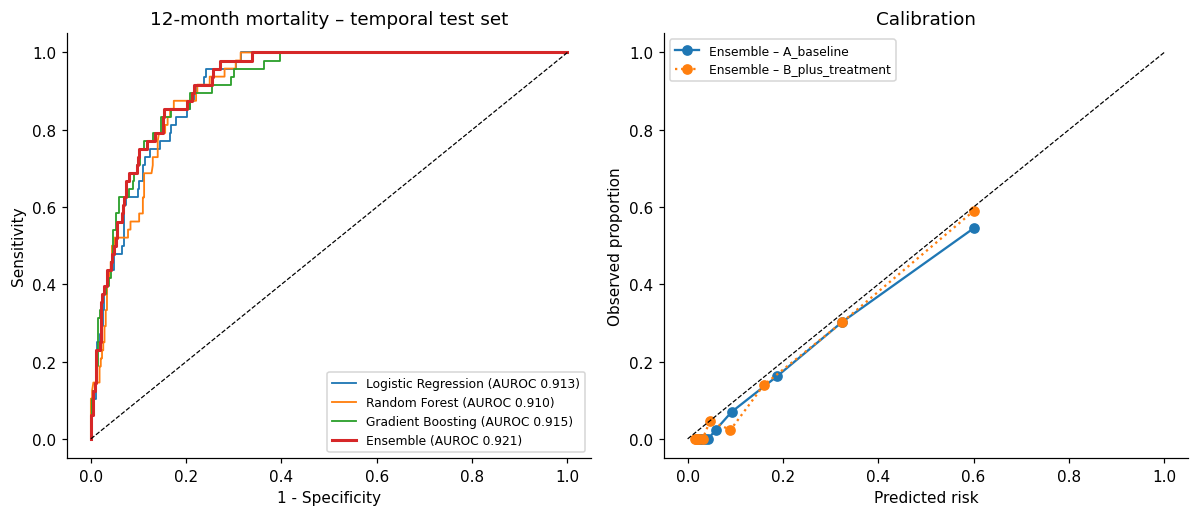

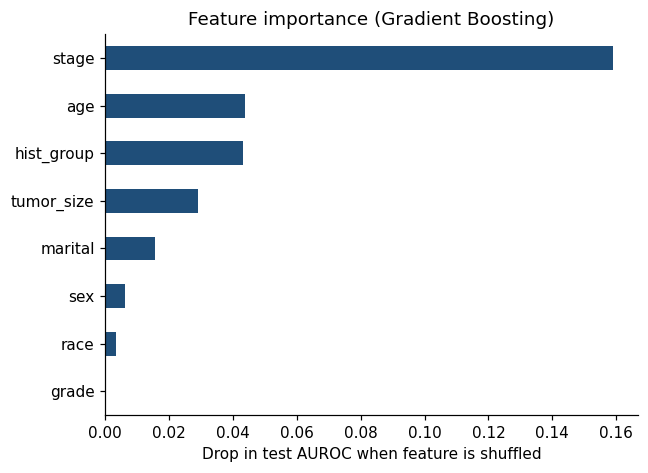

In [11]:
# ROC + calibration for the primary (baseline) feature set
fs = "A_baseline"; yte = test.y.values
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for name, p in test_preds[fs].items():
    fpr, tpr, _ = roc_curve(yte, p)
    axs[0].plot(fpr, tpr, lw=2 if name == "Ensemble" else 1.2, label=f"{name} (AUROC {roc_auc_score(yte, p):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[0].set_xlabel("1 - Specificity"); axs[0].set_ylabel("Sensitivity")
axs[0].set_title(f"{HORIZON}-month mortality – temporal test set"); axs[0].legend(loc="lower right", fontsize=8)
for fsn, ls in [("A_baseline", "-"), ("B_plus_treatment", ":")]:
    pt, pp = calibration_curve(yte, test_preds[fsn]["Ensemble"], n_bins=10, strategy="quantile")
    axs[1].plot(pp, pt, marker="o", ls=ls, label=f"Ensemble – {fsn}")
axs[1].plot([0, 1], [0, 1], "k--", lw=0.8); axs[1].set_xlabel("Predicted risk"); axs[1].set_ylabel("Observed proportion")
axs[1].set_title("Calibration"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_roc_calibration.png", dpi=300); plt.show()

# permutation importance (gradient boosting, baseline set)
feats = FEATURE_SETS[fs]; gb = fitted[fs]["Gradient Boosting"]
sub = test.sample(min(4000, len(test)), random_state=SEED)
pi = permutation_importance(gb, sub[feats], sub.y.values, n_repeats=5, scoring="roc_auc", random_state=SEED)
imp = pd.Series(pi.importances_mean, index=feats).sort_values()
imp.to_csv(f"{OUT}/permutation_importance.csv")
fig, ax = plt.subplots(figsize=(6, 0.4 * len(imp) + 1.2)); imp.plot.barh(ax=ax, color="#1f4e79")
ax.set_xlabel("Drop in test AUROC when feature is shuffled"); ax.set_title("Feature importance (Gradient Boosting)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_feature_importance.png", dpi=300); plt.show()

## 8. Auto-generated numbers for your manuscript

In [12]:
all_r = km_tab.set_index("Group")
best = res_ml[(res_ml.FeatureSet == "A_baseline") & (res_ml.Model == "Ensemble")].iloc[0]
lines = []
lines.append(f"COHORT: {len(raw):,} records -> {len(d):,} patients with pancreatic cancer diagnosed {YEAR_MIN}-{YEAR_MAX} (first/only primary, valid survival). Median age {d.age.median():.0f} y; {(d.sex=='Male').mean():.1%} male.")
lines.append(f"SURVIVAL: median OS {all_r.loc['All patients','Median OS (mo)']:.1f} months (95% CI {all_r.loc['All patients','Median 95% CI']}); 1-yr {all_r.loc['All patients','12-mo OS']}; 2-yr {all_r.loc['All patients','24-mo OS']}.")
for st in ["Localized", "Regional", "Distant"]:
    if st in all_r.index:
        lines.append(f"  {st}: n={all_r.loc[st,'N']:,}, median {all_r.loc[st,'Median OS (mo)']:.1f} mo ({all_r.loc[st,'Median 95% CI']}), 1-yr {all_r.loc[st,'12-mo OS']}")
if "stage_Distant" in res.index:
    r_ = res.loc["stage_Distant"]; lines.append(f"COX: distant vs localized HR {r_.HR:.2f} (95% CI {r_.CI_low:.2f}-{r_.CI_high:.2f}); model C-index {cph.concordance_index_:.3f}.")
lines.append(f"PREDICTION ({HORIZON}-mo mortality, baseline features, temporal validation train<{TEST_FROM}/test>={TEST_FROM}): train n={len(train):,}, test n={len(test):,}; "
             f"ensemble test AUROC {best.Test_AUROC:.3f} (95% CI {best.AUROC_CI}), AUPRC {best.Test_AUPRC:.3f}, Brier {best.Brier:.3f}.")
lines.append(f"AT {TARGET_SENS:.0%}-SENSITIVITY THRESHOLD (chosen on training OOF data): test sensitivity {best.Sensitivity:.3f}, specificity {best.Specificity:.3f}, PPV {best.PPV:.3f}, NPV {best.NPV:.3f}.")
lines.append("LIMITATIONS TO STATE: SEER has no symptom, BMI, family-history or lab data; prognosis (not diagnostic triage) in patients already diagnosed; registry data, no external validation; treatment variables subject to immortal-time bias (set B exploratory); PH assumption checked via Schoenfeld test.")
txt = "\n\n".join(lines); open(f"{OUT}/manuscript_numbers.txt", "w").write(txt); print(txt)

COHORT: 266,170 records -> 1,466 patients with pancreatic cancer diagnosed 2004-2022 (first/only primary, valid survival). Median age 27 y; 37.4% male.

SURVIVAL: median OS inf months (95% CI 191.0-inf); 1-yr 82.0% (79.9%-83.9%); 2-yr 74.8% (72.5%-77.0%).

  Localized: n=656, median inf mo (inf-inf), 1-yr 97.9% (96.5%-98.8%)

  Regional: n=297, median inf mo (155.0-inf), 1-yr 87.7% (83.3%-91.0%)

  Distant: n=445, median 15.0 mo (12.0-19.0), 1-yr 54.1% (49.3%-58.7%)

COX: distant vs localized HR 13.16 (95% CI 9.17-18.88); model C-index 0.870.

PREDICTION (12-mo mortality, baseline features, temporal validation train<2018/test>=2018): train n=834, test n=433; ensemble test AUROC 0.921 (95% CI 0.888-0.949), AUPRC 0.570, Brier 0.067.

AT 95%-SENSITIVITY THRESHOLD (chosen on training OOF data): test sensitivity 0.917, specificity 0.748, PPV 0.312, NPV 0.986.

LIMITATIONS TO STATE: SEER has no symptom, BMI, family-history or lab data; prognosis (not diagnostic triage) in patients already di

In [13]:
site_col = "Primary Site - labeled"
print("Rows:", len(raw))

print("\n--- Site recode ICD-O-3/WHO 2008 ---")
print(raw["Site recode ICD-O-3/WHO 2008"].value_counts().head(10))

print("\n--- Primary Site - labeled (top 10) ---")
print(raw[site_col].value_counts().head(10))
print("\nRows with C25 in labeled site:", raw[site_col].str.contains("C25", na=False).sum())

print("\n--- Age groups ---")
print(raw["Age recode with <1 year olds and 90+"].value_counts().sort_index().to_string())

print("\n--- Year of diagnosis ---")
print(raw["Year of diagnosis"].value_counts().sort_index().to_string())

Rows: 266170

--- Site recode ICD-O-3/WHO 2008 ---
Site recode ICD-O-3/WHO 2008
91                                  24218
92                                  17795
Rectosigmoid Junction               17384
Chronic Lymphocytic Leukemia        16456
Stomach                             15635
Anus, Anal Canal and Anorectum      13536
Esophagus                           13271
Small Intestine                     11286
24                                  11256
Other Myeloid/Monocytic Leukemia    11189
Name: count, dtype: int64

--- Primary Site - labeled (top 10) ---
Primary Site - labeled
C12.9-Pyriform sinus    17419
176                     15987
389                     14259
405                     11996
C44.1-Eyelid            11071
C42.1-Bone marrow       11060
C44.5-Skin of trunk     10091
457                      9567
177                      9093
196                      8010
Name: count, dtype: int64

Rows with C25 in labeled site: 2000

--- Age groups ---
Age recode with <1 year old

In [14]:
print(raw[colmap["age"][0]].value_counts().head(15))     # confirm the age restriction
print(len(test), test.y.sum(), test.y.mean())             # test events and prevalence
# stage-only baseline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
oh = OneHotEncoder(handle_unknown="ignore")
lr = LogisticRegression(max_iter=1000).fit(oh.fit_transform(train[["stage"]]), train.y)
print(roc_auc_score(test.y, lr.predict_proba(oh.transform(test[["stage"]]))[:,1]))
print(ph.summary.round(4))                                # save the Schoenfeld result

Age recode with <1 year olds and 90+
55-59 years    34362
00 years       19327
85-89 years    18537
20-24 years    18212
01-04 years    16336
65-69 years    15708
20             14168
70-74 years    13542
40-44 years    13443
90+ years      13369
75-79 years     9456
60-64 years     9319
21              8597
80-84 years     8411
15-19 years     7326
Name: count, dtype: int64
433 48 0.11085450346420324
0.8708062770562771
                                                 test_statistic       p  \
age_per10yr                                              0.0740  0.7856   
dx_year_per5                                             0.4369  0.5086   
grade_G2                                                 0.0258  0.8724   
grade_G3-4                                               0.9265  0.3358   
grade_Unknown                                            0.2597  0.6104   
hist_group_Neuroendocrine                                2.2282  0.1355   
hist_group_Other                                   

In [15]:
mask = raw["Primary Site - labeled"].str.contains("C25", na=False)
print("Pancreas rows sit at index:", mask[mask].index.min(), "to", mask[mask].index.max())
print(raw.iloc[[0, 1999, 2000, 2001, 100000, 200000]].T.iloc[:10])

Pancreas rows sit at index: 0 to 1999
                                                                  0       \
Age recode with <1 year olds and 90+                            00 years   
Sex                                                                 Male   
Year of diagnosis                                                   2010   
Race and origin recode (NHW, NHB, NHAIAN, NHAPI...  Hispanic (All Races)   
Site recode ICD-O-3/WHO 2008                                    Pancreas   
Behavior code ICD-O-3                                          Malignant   
TNM 7/CS v0204+ Schema recode                           PancreasBodyTail   
Primary Site                                                         252   
Behavior recode for analysis                                   Malignant   
Grade Recode (thru 2017)                                         Unknown   

                                                                1999    \
Age recode with <1 year olds and 90+               

## 9. Download everything

In [16]:
zpath = "oncosense_results.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT)): z.write(os.path.join(OUT, f), f)
print("Saved:", sorted(os.listdir(OUT)))
try:
    from google.colab import files; files.download(zpath)
except ImportError:
    pass

Saved: ['cohort_flow.csv', 'cox_hazard_ratios.csv', 'fig1_km_by_stage.png', 'fig2_cox_forest.png', 'fig3_roc_calibration.png', 'fig4_feature_importance.png', 'km_summary.csv', 'manuscript_numbers.txt', 'ml_results.csv', 'permutation_importance.csv', 'table1.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from sklearn.linear_model import LogisticRegression
from scipy.optimize import minimize_scalar
yte, ytr = test.y.values, train.y.values

# 1) Stage-only benchmark (same CV / threshold procedure as the other models)
so = make_models(["stage"])["Logistic Regression"]
oof_so = cross_val_predict(so, train[["stage"]], ytr, cv=skf, method="predict_proba")[:, 1]
so.fit(train[["stage"]], ytr); p_so = so.predict_proba(test[["stage"]])[:, 1]
lo, hi = boot_ci(yte, p_so, roc_auc_score)
thr = thr_at_sens(ytr, oof_so, TARGET_SENS)
row = dict(FeatureSet="stage_only", Model="Stage-only LR", CV_AUROC_train=roc_auc_score(ytr, oof_so),
           Test_AUROC=roc_auc_score(yte, p_so), AUROC_CI=f"{lo:.3f}-{hi:.3f}",
           Test_AUPRC=average_precision_score(yte, p_so), Brier=brier_score_loss(yte, p_so), Threshold=thr)
row.update(op_metrics(yte, p_so, thr))
so_row = pd.DataFrame([row]); display(so_row.round(3))
pd.concat([res_ml, so_row]).to_csv(f"{OUT}/ml_results.csv", index=False)

# 2) Paired bootstrap: ensemble (set A) minus stage-only, and minus logistic regression
p_ens = test_preds["A_baseline"]["Ensemble"]
p_lr  = test_preds["A_baseline"]["Logistic Regression"]
rng = np.random.default_rng(SEED); d_so, d_lr = [], []
for _ in range(N_BOOT):
    b = rng.integers(0, len(yte), len(yte))
    if yte[b].min() == yte[b].max(): continue
    d_so.append(roc_auc_score(yte[b], p_ens[b]) - roc_auc_score(yte[b], p_so[b]))
    d_lr.append(roc_auc_score(yte[b], p_ens[b]) - roc_auc_score(yte[b], p_lr[b]))
for nm, v in [("Ensemble - stage-only", d_so), ("Ensemble - logistic regression", d_lr)]:
    print(f"AUROC difference {nm}: {np.mean(v):+.3f} "
          f"(95% CI {np.percentile(v,2.5):+.3f} to {np.percentile(v,97.5):+.3f})")

# 3) Calibration slope and intercept (ensemble, feature sets A and B)
def cal(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    slope = LogisticRegression(C=1e10, max_iter=1000).fit(z, y).coef_[0, 0]
    f = lambda a: -np.sum(y * (a + z[:, 0]) - np.log1p(np.exp(a + z[:, 0])))
    return slope, minimize_scalar(f).x   # intercept = calibration-in-the-large (slope fixed at 1)

for fsn in ["A_baseline", "B_plus_treatment"]:
    s, a = cal(yte, test_preds[fsn]["Ensemble"])
    print(f"{fsn} ensemble: calibration slope {s:.2f}, intercept {a:+.2f}")

,FeatureSet,Model,CV_AUROC_train,Test_AUROC,AUROC_CI,Test_AUPRC,Brier,Threshold,Sensitivity,Specificity,PPV,NPV
0,stage_only,Stage-only LR,0.788,0.871,0.824-0.911,0.375,0.074,0.081,0.958,0.623,0.241,0.992


AUROC difference Ensemble - stage-only: +0.050 (95% CI +0.017 to +0.084)
AUROC difference Ensemble - logistic regression: +0.008 (95% CI -0.001 to +0.018)
A_baseline ensemble: calibration slope 1.32, intercept -0.39
B_plus_treatment ensemble: calibration slope 1.25, intercept -0.30
